# Distribution Statistics in R

This notebook follows the analysis sequence. Each step explains the operation being performed; data and computational formulas are retained. Run all cells locally to refresh the saved figures.


## Census inspection


In [1]:
# Load the semicolon-delimited census sample and inspect the initial records.
US_census <- read.table("data/census_respondents.csv",  sep=";",header = TRUE)
head(US_census)

,respondent_age,employment_category,record_reference,education_level,education_years,marital_category,occupation_group,household_role,demographic_group,sex_label,capital_gain,capital_loss,work_hours_week,country_of_origin,income_band
,<int>,<chr>,<int>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<chr>
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
5,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
6,49,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K


In [2]:
# Review descriptive summaries across the census attributes.
summary(US_census)

 respondent_age  employment_category record_reference  education_level   
 Min.   :17.00   Length:4575         Min.   :  19302   Length:4575       
 1st Qu.:28.00   Class :character    1st Qu.: 117528   Class :character  
 Median :37.00   Mode  :character    Median : 179186   Mode  :character  
 Mean   :38.69                       Mean   : 190852                     
 3rd Qu.:48.00                       3rd Qu.: 241390                     
 Max.   :90.00                       Max.   :1033222                     
                                                                         
 education_years marital_category   occupation_group   household_role    
 Min.   : 1.00   Length:4575        Length:4575        Length:4575       
 1st Qu.: 9.00   Class :character   Class :character   Class :character  
 Median :10.00   Mode  :character   Mode  :character   Mode  :character  
 Mean   :10.08                                                           
 3rd Qu.:12.00                        

In [3]:
# Determine how many census observations are available.
nrow(US_census)

[1] 4575

## Age: location, scale, and shape


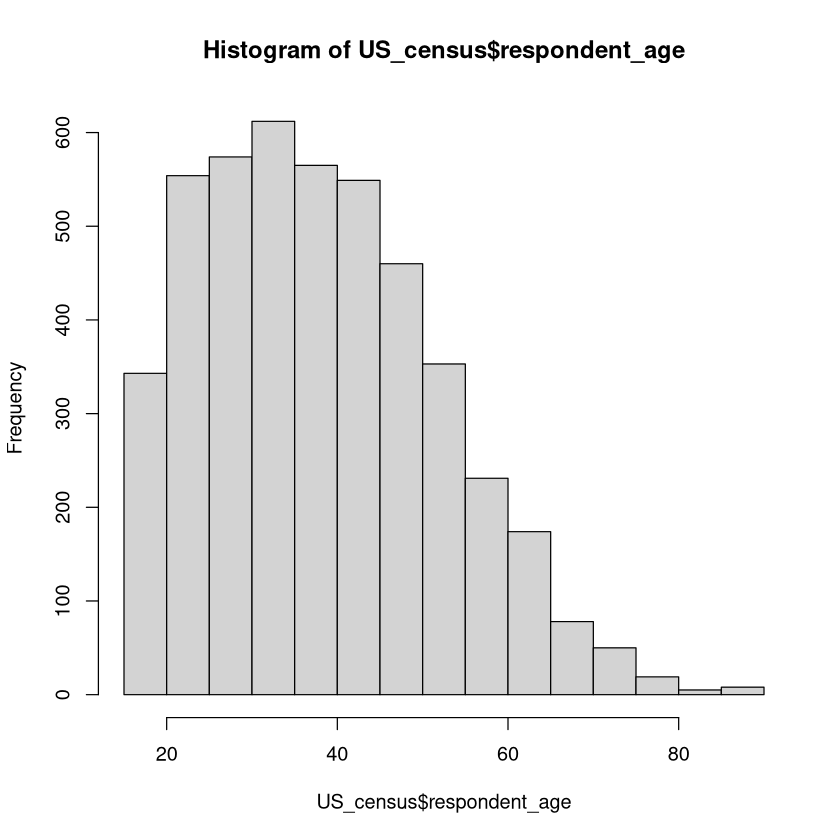

In [4]:
# Display the distribution of respondent ages.
hist(US_census$respondent_age)

In [5]:
# Compute the untrimmed mean age.
mean(US_census$respondent_age)

[1] 38.6859

In [6]:
# Estimate a 10% trimmed mean to reduce sensitivity to extremes.
mean(US_census$respondent_age, trim=0.10)

[1] 37.8088

In [7]:
# Compute the median age.
median(US_census$respondent_age)

[1] 37

In [8]:
# Measure the sample standard deviation.
sd(US_census$respondent_age)

[1] 13.63669

In [9]:
# Identify the most frequent age value or values.
my_mode <- table(US_census$respondent_age) 
my_mode 
my_mode[which(my_mode ==max(my_mode))] 


 17  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36 
 54  69 103 117  92 106 122 111 123 111 116 116 110 121 146 111 101 126 128 111 
 37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54  55  56 
119 110 107 118 123 104 117 108  97 113 106  71  89  81  93  73  72  61  54  48 
 57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72  73  74  75  76 
 53  44  51  35  48  25  41  35  25  22  19  17  11   9  10  12   7  10  11   8 
 77  78  79  80  81  82  83  88  90 
  4   2   2   3   3   1   1   1   7 

31 
146

In [10]:
# Find minimum, maximum, and overall range.
min(US_census$respondent_age)
max(US_census$respondent_age)
range(US_census$respondent_age)

[1] 17

[1] 90

[1] 17 90

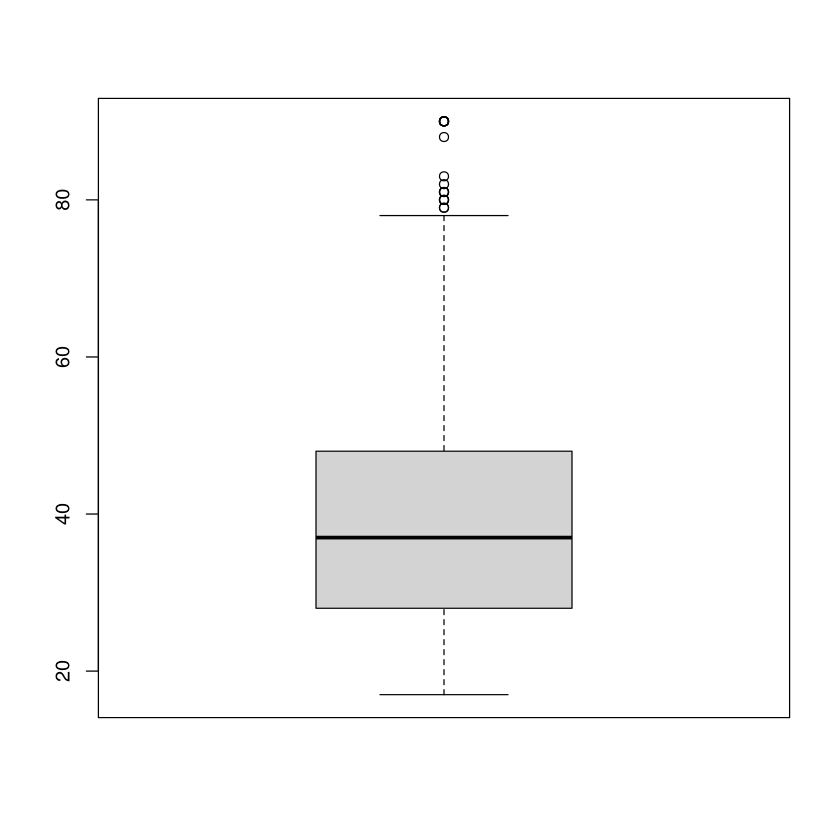

In [11]:
# Inspect age spread and unusual values with a boxplot.
boxplot(US_census$respondent_age)

In [14]:
# Estimate the skewness of the age distribution.
library(moments) 
skewness(US_census$respondent_age)

[1] 0.545784

In [15]:
# Estimate kurtosis to summarize distribution tails.
kurtosis(US_census$respondent_age)

[1] 2.831909

## Simulated distributions and normality diagnostics


[1] 4 4 3 5 3 3 2 3 3 4 3 2 4 3 2


	Shapiro-Wilk normality test

data:  x
W = 0.88164, p-value = 0.0502


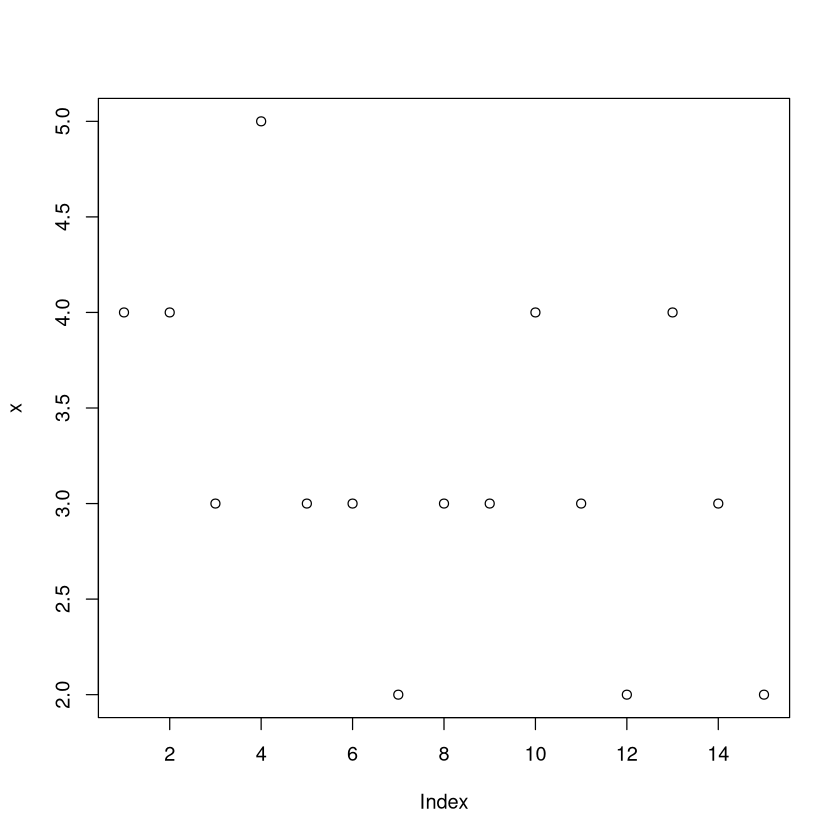

In [16]:
# Generate a reproducible binomial sample and run a Shapiro–Wilk test.
set.seed(100)
x <- rbinom(15,5,.6) 
x
plot(x)
shapiro.test(x) 


	Shapiro-Wilk normality test

data:  x
W = 0.94053, p-value = 0.2453


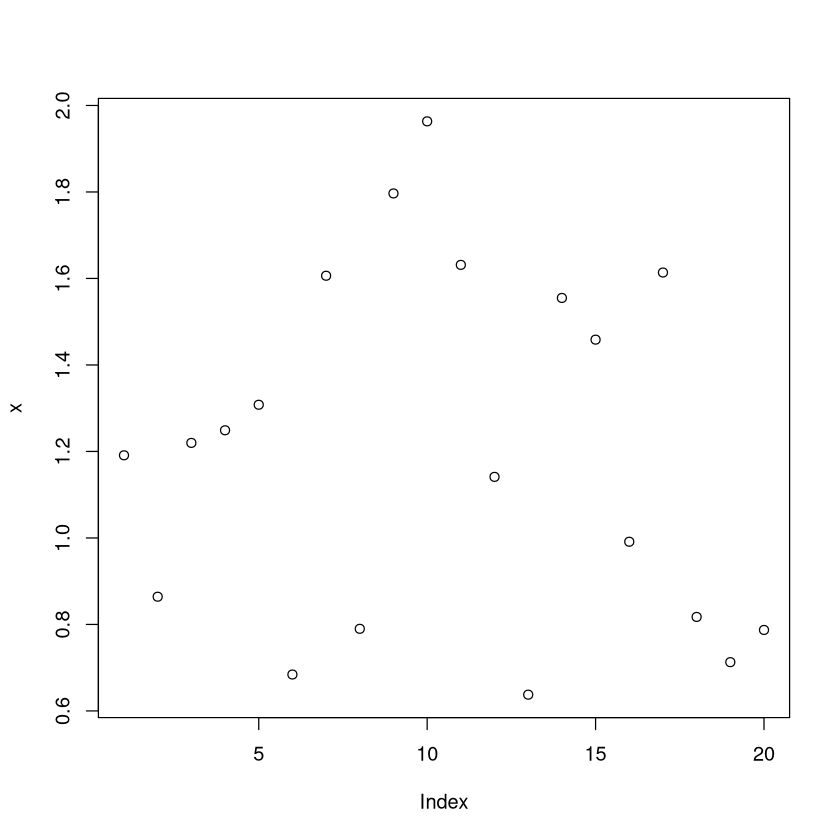

In [17]:
# Inspect a lognormal sample and its normality-test output.
x <- rlnorm(20,0,.4)
shapiro.test(x)
plot(x)


	Anderson-Darling normality test

data:  x
A = 1.1003, p-value = 0.006975


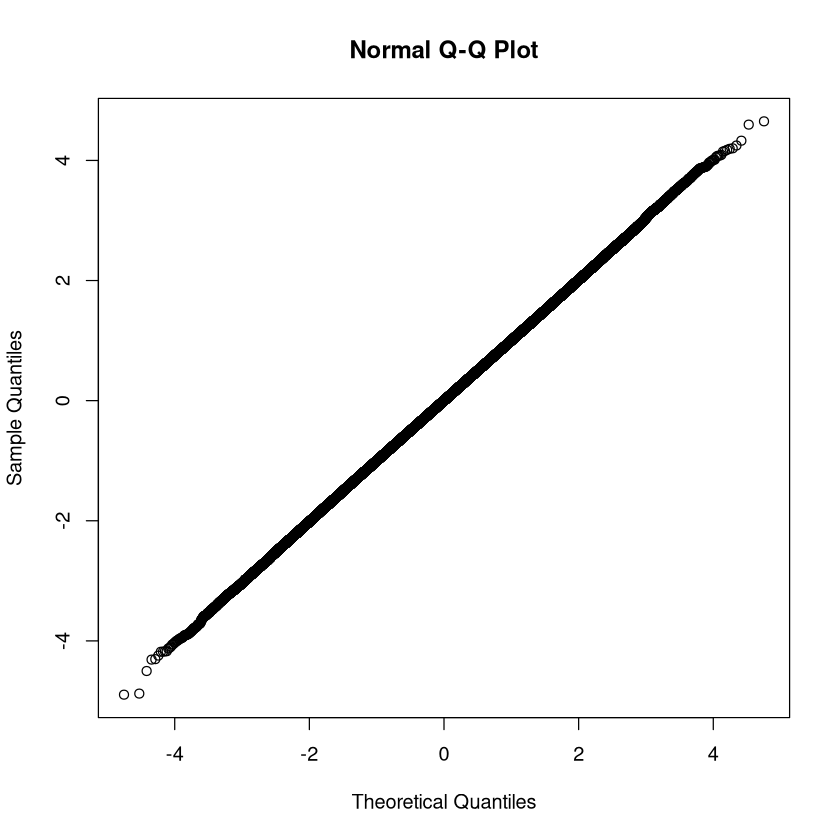

In [19]:
# Use a larger Student-t sample for the Anderson–Darling test and Q–Q plot.
library(nortest) 
x <- rt(500000,200)
ad.test(x)
qqnorm(x)